# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

# TODO: print the shape and the dtypes of patients
print("Shape of patients DataFrame:", patients.shape)
print("Data types of patients DataFrame:")
print(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_point(filled=True, size=90).encode(
    x=alt.X("sessions_attended:Q", title="Sessions attended (of 36)"),
    y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False),
        ),
    color=alt.Color("program:N", title="Program"),
    shape=alt.Shape("program:N", title="Program"),
        tooltip=[
            "patient_id",
            "sessions_attended",
            "walk_distance_m",
            "program",
        ],
    ).properties(title="Walk distance by sessions attended, by program")  # TODO: the Altair scatter plot README Task 1.1 describes

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
#  output/exploratory_spec.json draws circle marks, not points; in Task 1.1, use .mark_point(), the one mark that shows the shape encoding.

exploratory_chart.save(EXPLORATORY_SPEC_PATH)
exploratory_chart.show()

Shape of patients DataFrame: (12, 4)
Data types of patients DataFrame:
patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object


alt.Chart(...)

### 1.2 Describe what the chart shows

- Question: If patients who attended more exercise sessions walked farther in the six-minute walk test(SMWT), and if the relationship differs between the home based and center based sessions.
- Each point: Each point represents individual patient, it reveals the infomration of sessions attended(x axis) and six-minute walk distance(y axis).
- Pattern: Patients attended more exercise sessions have better performance in SWMT, as session attendence increase the distance in six-minute walk increases along. Two programs followed the roughly same trend, but center based patients slightly performed better than home based patients.
- Can show reason: Since healthier patients might attend more sessions and have better performance, we cannot determine if the longer walk is from more session attendence or the participants are healthier.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


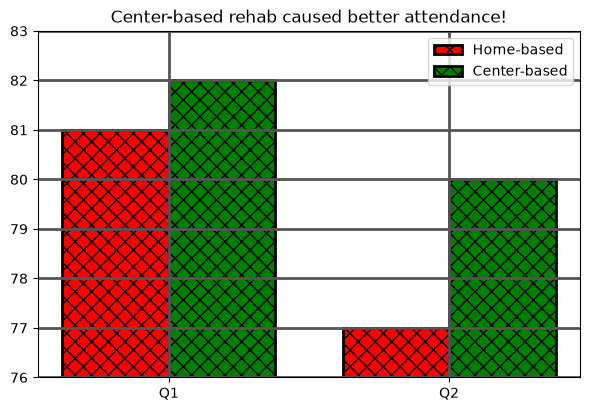

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", 
     "problem": "The title says center based rehab caused better attendence, but the table only shows slight differences between two types of programs, and cannot prove the claim.", 
     "repair": "Use a descriptive title: Attendance rate in home based and center based programs from Q1 to Q2"},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", 
     "problem": "The y-axis starts at 76%, so center-based's Q2 lead (80% vs 77%) is drawn as a 3 times difference in bar length.", 
     "repair": "Start the y-axis at 0% to accurately represent the differences."},
    {"category": "missing unit", 
     "problem": "The y axis does not have a unit label. Then the reader cannot understand what the numbers mean.", 
     "repair": "Add a unit label to the y-axis, e.g., 'Percentage' or '%'."},
    {"category": "color-only encoding", 
     "problem": "The plot use red and green to distinguish the two programs and the patterns and textures are the same. This is not accessible to colorblind readers.", 
     "repair": "Use colorblind poeple friendly colors and add patterns or labels in addition to colors to distinguish the two programs."},
    {"category": "distracting decoration", 
     "problem": "'Thick black edges, a heavy grid with lines drawn over the bars, and the same dense hatch on every bar carry no data.", 
     "repair": "Drop the edges, lighten the grid and put it behind the bars, hide the top and right spines, and keep hatches only where they mark the program."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title says center based rehab caused better attendence, but the table only shows slight differences between two types of programs, and cannot prove the claim.
    repair: Use a descriptive title: Attendance rate in home based and center based programs from Q1 to Q2
truncated baseline: The y-axis starts at 76%, so center-based's Q2 lead (80% vs 77%) is drawn as a 3 times difference in bar length.
    repair: Start the y-axis at 0% to accurately represent the differences.
missing unit: The y axis does not have a unit label. Then the reader cannot understand what the numbers mean.
    repair: Add a unit label to the y-axis, e.g., 'Percentage' or '%'.
color-only encoding: The plot use red and green to distinguish the two programs and the patterns and textures are the same. This is not accessible to colorblind readers.
    repair: Use colorblind poeple friendly colors and add patterns or labels in addition to colors to distinguish the two programs.
distracting decorat

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

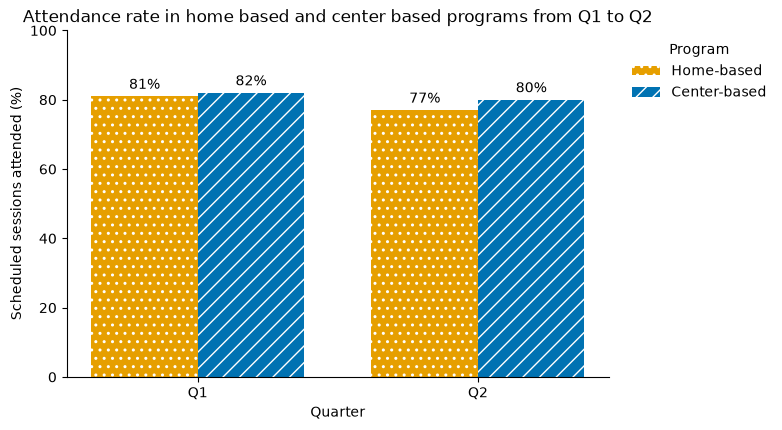

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)
                              
home_bars = redesign_ax.bar(x - width / 2, home, width, label="Home-based",
                            color=ORANGE, hatch="..", edgecolor="white", linewidth=0)
center_bars = redesign_ax.bar(x + width / 2, center, width, label="Center-based",
                              color=BLUE, hatch="//", edgecolor="white", linewidth=0)


for bars in (home_bars, center_bars):
    redesign_ax.bar_label(bars, fmt="%d%%", padding=3)

# Zero baseline, because bar length encodes the value
redesign_ax.set_ylim(0, 100)

# Axis labels with units, quarter ticks
redesign_ax.set_xticks(x, quarters)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")

redesign_ax.set_title("Attendance rate in home based and center based programs from Q1 to Q2")

redesign_ax.grid(False)
redesign_ax.spines[["top", "right"]].set_visible(False)

redesign_ax.legend(title="Program", loc="upper left",
                   bbox_to_anchor=(1.02, 1), frameon=False)
redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")
plt.show()

y_low, y_high = redesign_ax.get_ylim()
# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"
redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
from pandas import plotting


followup = pd.read_csv(FOLLOWUP_PATH)  # TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup
display(followup)

question = "How does the share of patients meeting their rehab goal change from visit 1 to visit 4 in the home-based and center-based programs?"  # TODO: the comparison the chart should help the coordinator make
audience = "The rehab program coordinator, who will use the chart to compare how the two programs' goal attainment progresses across follow-up visits." # TODO: who reads the chart and what they will use it for
intended_claim = "Goal attainment rose in both programs from visit 1 to visit 4, more for center-based than home-based."# TODO: the one descriptive conclusion the chart supports
y_measure = "Patients seen at the visit who met their goal (%)"  # TODO: what the y-axis measures, with its unit
grain = "One row of the plotting table, and one point on a line, is one program at one follow-up visit number; goal_met_pct is already aggregated from individualpatients seen at that visit, so each point summarizes 44 to 52 patients." # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]  # TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)
print("shape:", supporting_data.shape)
print("same as saved:", supporting_data.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

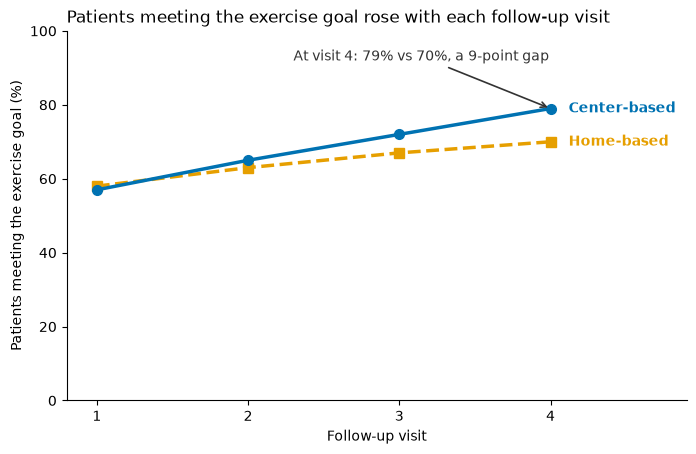

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes

explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"],
                    color=ORANGE, marker="s", linestyle="--",
                    linewidth=2.5, markersize=7)
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"],
                    color=BLUE, marker="o", linestyle="-",
                    linewidth=2.5, markersize=7)
explanatory_ax.text(4.12, home_goals["goal_met_pct"].iloc[-1], "Home-based",
                    color=ORANGE, va="center", fontweight="bold")
explanatory_ax.text(4.12, center_goals["goal_met_pct"].iloc[-1], "Center-based",
                    color=BLUE, va="center", fontweight="bold")
explanatory_ax.annotate(
    "At visit 4: 79% vs 70%, a 9-point gap",
    xy=(4, 79), xytext=(2.3, 92),
    arrowprops=dict(arrowstyle="->", color="#333333", linewidth=1.2),
    fontsize=10, color="#333333")
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_xlim(0.8, 4.9)
explanatory_ax.set_ylim(0, 100)

explanatory_ax.set_title("Patients meeting the exercise goal rose with each follow-up visit",loc="left")
# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_ax.spines[["top", "right"]].set_visible(False)
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
critique

[{'category': 'unsupported claim',
  'problem': 'The title says center based rehab caused better attendence, but the table only shows slight differences between two types of programs, and cannot prove the claim.',
  'repair': 'Use a descriptive title: Attendance rate in home based and center based programs from Q1 to Q2'},
 {'category': 'truncated baseline',
  'problem': "The y-axis starts at 76%, so center-based's Q2 lead (80% vs 77%) is drawn as a 3 times difference in bar length.",
  'repair': 'Start the y-axis at 0% to accurately represent the differences.'},
 {'category': 'missing unit',
  'problem': 'The y axis does not have a unit label. Then the reader cannot understand what the numbers mean.',
  'repair': "Add a unit label to the y-axis, e.g., 'Percentage' or '%'."},
 {'category': 'color-only encoding',
  'problem': 'The plot use red and green to distinguish the two programs and the patterns and textures are the same. This is not accessible to colorblind readers.',
  'repair':

In [9]:
text_alternative = (
    "Line chart of the percentage of patients meeting the exercise goal (%) at "
    "follow-up visits 1 to 4, with one line for the home-based program and one for "
    "the center-based program. Both rise across the visits: home-based goes from 58% "
    "to 70%, and center-based from 57% to 79%, so the two start almost level and "
    "center-based finishes 9 points higher at visit 4 (79% against 70%). These are "
    "descriptive program summaries; patients chose their program, so the gap does not "
    "show that one program causes more exercise. Each percentage also covers only the "
    "patients seen at that visit, about 45 per program, so a 9-point gap could also "
    "come from chance or from which patients returned."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}   # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative


# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)
# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH
with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']
['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

**Answer：**
### 3.4 Review the saved charts

1. **Grayscale.** In `critique_redesign.png`, Home-based bars are filled with a dot pattern and Center-based bars with diagonal stripes, and the legend shows the same patterns, so the two programs stay distinct without color. Each bar also carries its value (81%, 82%, 77%, 80%). In `explanatory_chart.png`, Home-based is a dashed line with square markers and Center-based is a solid line with circle markers, and each line is named by a direct label at its right end, so a reader can identify them by line style, marker shape, and text.

2. **Annotation.** The arrow points to Center-based's visit-4 point at (4, 79). Its text, "At visit 4: 79% vs 70%, a 9-point gap", only restates two values in the table and their difference. It does not say why the gap exists or that either program caused it, so it stays within what the eight rows can show.

3. **Cut-off or overlapping text.** No text is cut off in either PNG. The legend in the redesign sits outside the right edge and is fully saved because of `bbox_inches="tight"`. In the explanatory chart, I set `set_xlim(0.8, 4.9)` to leave room for the right-end labels, and placed the annotation text at (2.3, 92), above both lines, so it does not cover the "Center-based" label or the data. The only near-overlap is at visit 1, where the two markers (57% and 58%) almost touch; this reflects the data, and the different marker shapes and line styles still separate them.

4. **Remaining limitation.** Patients chose their program, so the two groups may differ in motivation, health, or access before rehab starts; no design choice can turn this comparison into evidence that one program causes more attendance or exercise. The percentages also cover only the patients seen at each visit (about 45 per program, falling from 48 to 44 and from 52 to 47), so the rise and the 9-point gap could come from chance or from which patients kept returning. Answering that would need different data, such as randomization, patient-level records, or follow-up of those who stopped attending.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [10]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m